# Operation Limits: Must-Run and Full Load Hours

The [Capacity Limits notebook](21_capacity_limits.ipynb) limited how much of a component can be built. This notebook limits how it is operated. Two parameters are already known: `operationRateMax` limits the production of wind turbines and PV to their capacity factors, and `operationRateFix` fixes the electricity demand and the production of run-of-river plants. This notebook adds two more:

| Component | New parameter | What it does |
|---|---|---|
| Combined heat and power (CHP) plants | `operationRateMin` | a minimum operation in every time step, e.g. a must-run |
| Biogas power plants | `yearlyFullLoadHoursMax` | limits the yearly operation relative to the capacity, e.g. because the fuel is limited |

All of them belong to every component type with an operation.

## 1. Minimum, maximum or fixed operation

The operation of a component can be limited in every time step from below, from above or fixed, and over the whole year:

| | Minimum | Maximum | Fixed |
|---|---|---|---|
| **Every time step** | `operationRateMin` | `operationRateMax` | `operationRateFix` |
| **Sum over the year** | `yearlyFullLoadHoursMin` | `yearlyFullLoadHoursMax` | |

The time series parameters are `pd.DataFrame`s with one row per time step and one column per region, or dictionaries with one of them per investment period. What their values mean depends on `hasCapacityVariable`:

- **With a capacity variable**, the values are **relative to the capacity**: a value of 0.3 means 30 % of the capacity, as for the capacity factors of wind turbines and PV.
- **Without a capacity variable**, the values are **absolute**, in the unit of the commodity, as for the electricity demand.

The full load hours are the yearly operation divided by the capacity, i.e. the number of hours the component would need to produce its yearly output at full capacity. They need a capacity variable.

## 2. The model of the basic tutorial

In [1]:
import warnings

import pandas as pd

import fine as fn
from tutorialHelpers import (
    buildBasicTutorialModel,
    colormap,
    plotCapacityAndGeneration,
)

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

esM = buildBasicTutorialModel()

## 3. Must-run CHP plants with `operationRateMin`

Combined heat and power (CHP) plants produce electricity and heat for district heating networks at the same time. As long as the networks need heat, the plants have to run, whether or not their electricity is needed. Our model does not contain heat, so we only describe this obligation: from October to March, the CHP plants have to run with at least 50 % of their capacity in every hour. In the rest of the year, they may run, but do not have to.

We assume that 5 GW of gas CHP plants exist in each region (`capacityFix`), with an electrical efficiency of 40 %. Since the heat is not part of the model, all of their CO<sub>2</sub> counts for the electricity.

`operationRateMin` is a `pd.DataFrame` with one row per hour of the year and one column per region. The month of every hour is taken from a calendar of a year with 365 days:

In [2]:
months = pd.date_range("2021-01-01", periods=8760, freq="h").month
heatingSeason = months.isin([10, 11, 12, 1, 2, 3])

chpMustRun = pd.DataFrame(
    {"north": heatingSeason * 0.5, "south": heatingSeason * 0.5},
    index=range(8760),
)

esM.add(
    fn.Conversion(
        esM=esM,
        name="CHP plants",
        physicalUnit="GW_el",
        commodityConversionFactors={
            "electricity": 1,
            "naturalGas": -1 / 0.4,
            "CO2": 201e-6 / 0.4,
        },
        hasCapacityVariable=True,
        capacityFix=pd.Series({"north": 5, "south": 5}),  # GW
        operationRateMin=chpMustRun,
        opexPerCapacity=20,  # million Euro per GW and year
    )
)

## 4. Biogas power plants with `yearlyFullLoadHoursMax`

Biogas power plants are a CO<sub>2</sub>-neutral and flexible source of electricity. Their fuel, however, is limited: only so much biogas is produced from manure, residues and energy crops. We assume that there is enough biogas for **4000 full load hours per year**. With 1 GW of biogas power plants, the model can produce up to 4000 GWh per year and may choose freely in which hours. We do not model the biogas itself, so the plants are a `Source` of electricity, and the fuel cost is part of `opexPerOperation`.

In [3]:
esM.add(
    fn.Source(
        esM=esM,
        name="Biogas power plants",
        commodity="electricity",
        hasCapacityVariable=True,
        yearlyFullLoadHoursMax=4000,  # hours per year
        investPerCapacity=2000,  # million Euro per GW
        opexPerCapacity=80,  # million Euro per GW and year
        opexPerOperation=0.08,  # million Euro per GWh of electricity (including the fuel)
        interestRate=0.08,
        economicLifetime=20,
    )
)

## 5. Optimize

In [4]:
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (75 outputs left out)

Solved with barrier


    3754    5.8847636e+05   0.000000e+00   0.000000e+00      1s


Solved in 3754 iterations and 0.97 seconds (0.61 work units)


Optimal objective  5.884763605e+05


## 6. Results

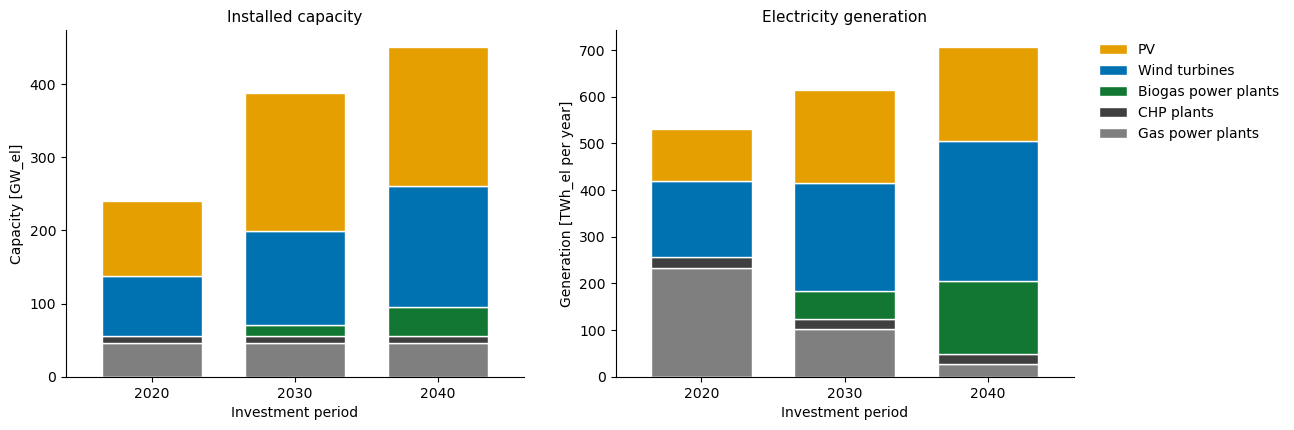

In [5]:
capacity, generation = plotCapacityAndGeneration(
    esM,
    ["Gas power plants", "CHP plants", "Biogas power plants", "Wind turbines", "PV"],
)

In [6]:
generation.round(0)  # TWh per year

component,Gas power plants,CHP plants,Biogas power plants,Wind turbines,PV
period,,,,,
2020,232.0,24.0,0.0,163.0,111.0
2030,102.0,22.0,60.0,231.0,200.0
2040,27.0,22.0,157.0,298.0,203.0


- The **CHP plants** produce about 22 TWh per year in 2030 and 2040. This is exactly their must-run: 2 regions × 2.5 GW × 4368 hours from October to March. Only in 2020 do they produce a little more.
- The **biogas power plants** are built from 2030 on. In 2040, about 39 GW produce 157 TWh. As flexible and CO<sub>2</sub>-neutral plants, they replace a large part of the wind turbines (about 300 TWh instead of 450 TWh in the basic tutorial) and of the gas power plants.

### The must-run of the CHP plants

The heat map of the CHP plants in the north in 2040 shows the must-run: from October to March, they never produce less than 2.5 GW (50 % of 5 GW), from April to September, they mostly stand still.

(<Figure size 900x300 with 2 Axes>,
 <Axes: xlabel='Day of the year', ylabel='Hour of the day'>)

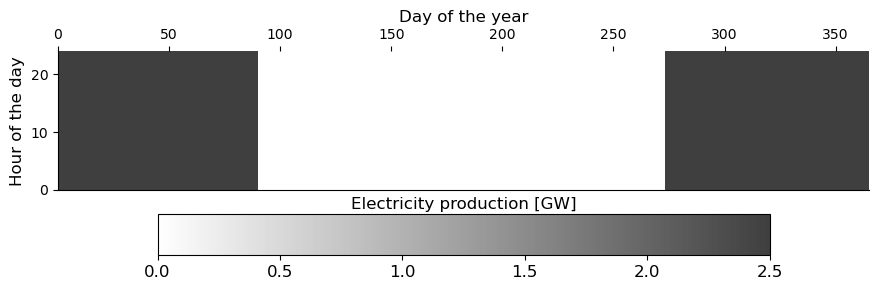

In [7]:
fn.plotOperationColorMap(
    esM,
    "CHP plants",
    "north",
    ip=2040,
    cmap=colormap("CHP plants"),
    figsize=(9, 3),
    xlabel="Day of the year",
    ylabel="Hour of the day",
    zlabel="Electricity production [GW]",
)

### The full load hours of the biogas power plants

The full load hours are the yearly operation divided by the capacity. Here they are for 2040, both regions together:

In [8]:
summary2040 = esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=2040)
fullLoadHours = pd.Series(
    {
        component: summary2040.loc[(component, "operation")].iloc[0].sum()
        / summary2040.loc[(component, "capacity")].iloc[0].sum()
        for component in ["Biogas power plants", "Wind turbines", "PV"]
    },
    name="Full load hours in 2040 [h]",
)
fullLoadHours.astype(float).round(0)

Biogas power plants    4000.0
Wind turbines          1794.0
PV                     1070.0
Name: Full load hours in 2040 [h], dtype: float64

The biogas power plants reach exactly the 4000 hours that are allowed: the limit is binding, so the model would like to use them more often. The full load hours of wind turbines and PV result from the weather and from the hours in which their production is not needed and curtailed.

(<Figure size 900x300 with 2 Axes>,
 <Axes: xlabel='Day of the year', ylabel='Hour of the day'>)

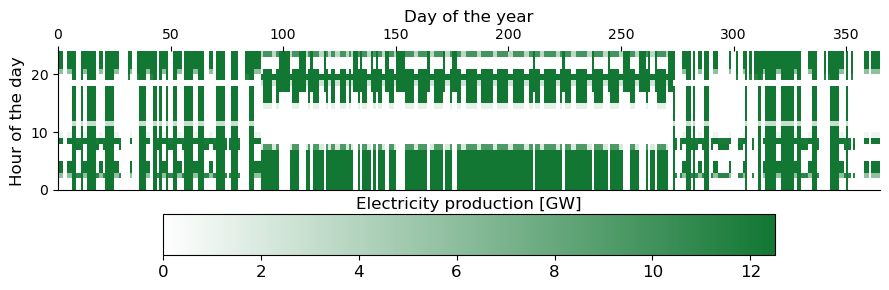

In [9]:
fn.plotOperationColorMap(
    esM,
    "Biogas power plants",
    "north",
    ip=2040,
    cmap=colormap("Biogas power plants"),
    figsize=(9, 3),
    xlabel="Day of the year",
    ylabel="Hour of the day",
    zlabel="Electricity production [GW]",
)

Since the biogas is limited, the model uses it in the hours in which it is most valuable: in summer at night, when PV does not produce, and in winter on days with little wind. Around noon in summer, the plants hardly ever run.

## Things to try

- Remove `operationRateMin` from the CHP plants. How much CO<sub>2</sub> do they emit then, and how much do the gas power plants produce instead?
- Change `yearlyFullLoadHoursMax` of the biogas power plants to 2000 hours. Does the model build more or fewer of them?
- Give the gas power plants a `yearlyFullLoadHoursMin` of 3000 hours, e.g. because they are only profitable with this many operating hours. What happens in 2040?

The next notebook, [Time Series Aggregation](31_time_series_aggregation.ipynb), shows how the typical days that all notebooks use are made and how many of them are needed.